# METR-LA — Data Audit & EDA (Project Check-in 1)

DSAN 6600 · Spatio-temporal traffic speed forecasting. Task: given the past 12 steps (1 h) of speed at all 207 sensors, predict the next 12 steps (15/30/60-min horizons).

Sections: **A** sanity · **B** missingness · **C** distributions · **D** temporal patterns · **E** long-term drift · **F** predictability · **G** spatial structure · **Eval** split, normalization, non-neural probes · **H** failure modes.
All figures are saved to `../figures/`. Missing readings are encoded as `0.0` in the raw file.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import acf

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data import (RAW_DIR, load_metr_la, load_adj, load_locations, missing_mask, time_features,
                      chrono_split, zscore_fit, make_windows, prepare_processed)
from src.metrics import horizon_report, masked_mae
from src.baselines import persistence, fit_historical_average, historical_average

SEED = 6600
rng = np.random.default_rng(SEED)
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.precision", 3); pd.set_option("display.max_rows", 20)

# palette: categorical slots 1-3 (validated all-pairs); single-hue sequential; neutral gray for context
C1, C2, C3, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
                     "lines.linewidth": 1.5})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show()

## A. Sanity checks

In [2]:
df = load_metr_la(RAW_DIR / "METR-LA.h5")
V = df.to_numpy()
Z = V == 0                      # missing mask (True = missing)
steps = df.index.to_series().diff().dropna().value_counts()
print(f"shape: {df.shape}  dtype: {V.dtype}  NaNs: {np.isnan(V).sum()}")
print(f"range: {df.index.min()} -> {df.index.max()}  ({(df.index.max()-df.index.min()).days + 1} days)")
print("time-step counts:", dict(steps))
print(f"min: {V.min()}  max: {V.max()}  overall zero rate: {Z.mean():.2%}")
assert df.shape == (34272, 207) and len(steps) == 1 and steps.index[0] == pd.Timedelta("5min")

shape: (34272, 207)  dtype: float64  NaNs: 0
range: 2012-03-01 00:00:00 -> 2012-06-27 23:55:00  (119 days)
time-step counts: {Timedelta('0 days 00:05:00'): np.int64(34271)}
min: 0.0  max: 70.0  overall zero rate: 8.11%


In [3]:
Vn = np.where(Z, np.nan, V)
stats = pd.DataFrame({
    "mean_nz": np.nanmean(Vn, 0), "std_nz": np.nanstd(Vn, 0), "min_nz": np.nanmin(Vn, 0),
    "max": V.max(0), "zero_rate": Z.mean(0), "frac_eq_70": (V == 70).mean(0),
}, index=df.columns).rename_axis("sensor_id")
stats.to_csv(FIG / "sensor_summary.csv")
display(stats.describe().T[["mean", "std", "min", "50%", "max"]])
display(stats.sort_values("mean_nz").iloc[[0, 1, 2, -3, -2, -1]])

,mean,std,min,50%,max
mean_nz,58.468,6.417,30.895,5.972e+01,67.727
std_nz,10.302,4.729,1.995,1.023e+01,23.939
min_nz,4.667,4.529,0.333,3.250e+00,34.125
max,69.902,0.551,65.000,7.000e+01,70.000
zero_rate,0.081,0.024,0.063,6.974e-02,0.201
frac_eq_70,0.005,0.019,0.000,5.252e-04,0.252


,mean_nz,std_nz,min_nz,max,zero_rate,frac_eq_70
sensor_id,,,,,,
771667,30.895,5.580,0.500,70.000,0.084,4.085e-04
771673,32.763,5.351,0.333,70.000,0.084,9.629e-04
773023,38.472,13.775,3.125,66.571,0.063,0.000e+00
767454,67.521,5.073,2.500,70.000,0.124,3.621e-02
767495,67.710,1.995,4.750,70.000,0.097,3.227e-02
767455,67.727,2.174,34.125,70.000,0.104,2.495e-02


**Takeaway.** The file is a clean, regular grid: 34,272 × 207 float64, 2012-03-01 → 2012-06-27 (119 days), every step exactly 5 min, no NaNs, values in [0, 70]. Sensors differ a lot: mean nonzero speed ranges from 30.9 mph (771667, a chronically congested segment) to 67.7 mph, so per-sensor behaviour (not just a global level) must be learned.

## B. Missingness (zeros)

overall zero rate 8.11%; timestamps with ALL sensors zero: 2148 (6.27%)
zero rate excluding full-outage timestamps: 1.97%
per-sensor zero rate: median 6.97%, p90 10.82%, max 20.10% (sensor 718076)


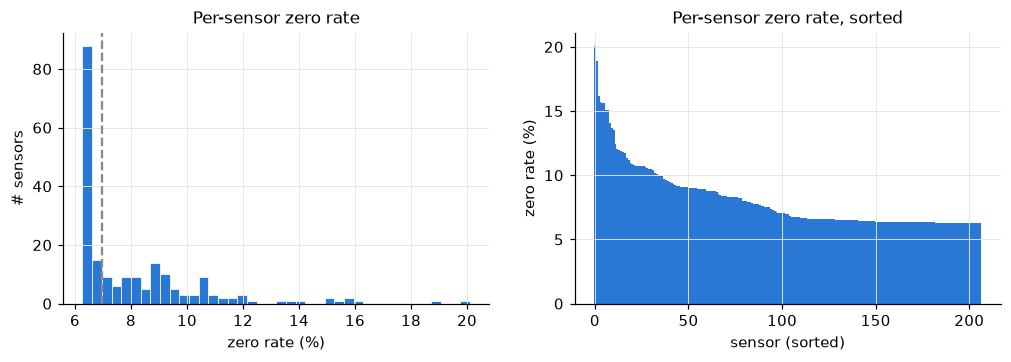

In [4]:
all_zero = Z.all(1)
print(f"overall zero rate {Z.mean():.2%}; timestamps with ALL sensors zero: {all_zero.sum()} ({all_zero.mean():.2%})")
print(f"zero rate excluding full-outage timestamps: {Z[~all_zero].mean():.2%}")
zr = stats["zero_rate"]
print("per-sensor zero rate: median {:.2%}, p90 {:.2%}, max {:.2%} (sensor {})".format(zr.median(), zr.quantile(.9), zr.max(), zr.idxmax()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(zr * 100, bins=40, color=C1, edgecolor="white", linewidth=0.5)
ax[0].axvline(zr.median() * 100, color=GRAY, ls="--"); ax[0].set(xlabel="zero rate (%)", ylabel="# sensors", title="Per-sensor zero rate")
s = zr.sort_values(ascending=False) * 100
ax[1].bar(range(len(s)), s.values, color=C1, width=1.0)
ax[1].set(xlabel="sensor (sorted)", ylabel="zero rate (%)", title="Per-sensor zero rate, sorted")
save(fig, "B1_zero_rate_per_sensor")

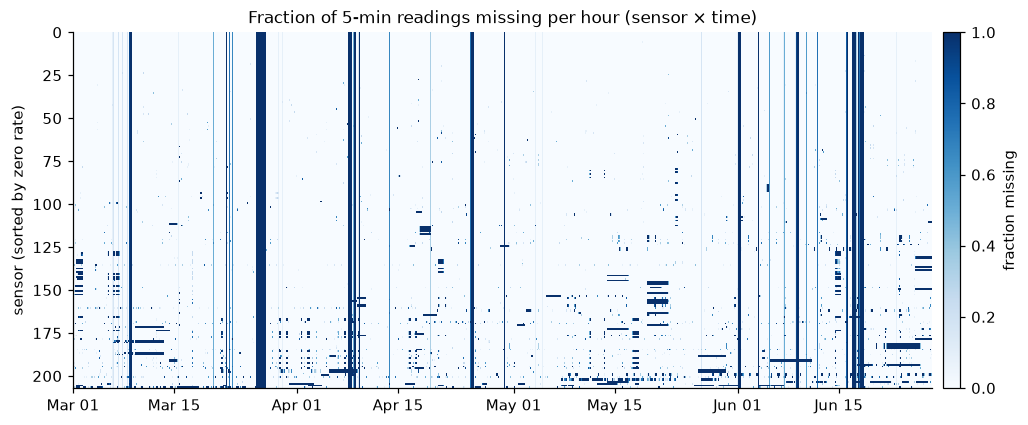

In [5]:
hourly = pd.DataFrame(Z, index=df.index, columns=df.columns).resample("h").mean()
order = zr.sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(hourly[order].T.values, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest",
               extent=[mdates.date2num(hourly.index[0]), mdates.date2num(hourly.index[-1]), len(order), 0])
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.grid(False)
ax.set(ylabel="sensor (sorted by zero rate)", title="Fraction of 5-min readings missing per hour (sensor × time)")
fig.colorbar(im, ax=ax, label="fraction missing", pad=0.01)
save(fig, "B2_missing_heatmap")

In [6]:
run_id = np.cumsum(np.r_[True, all_zero[1:] != all_zero[:-1]])
runs = (pd.DataFrame({"t": df.index, "z": all_zero, "run": run_id}).query("z")
        .groupby("run").agg(start=("t", "min"), end=("t", "max"), steps=("t", "size")))
runs["duration"] = pd.to_timedelta(runs["steps"] * 5, unit="min")
runs = runs.reset_index(drop=True)
print(f"{len(runs)} full-outage runs, total {runs.steps.sum()} steps; "
      f"median {runs.duration.median()}, longest {runs.duration.max()}; runs >= 1h: {(runs.steps >= 12).sum()}")
runs.to_csv(FIG / "outage_runs.csv", index=False)
display(runs.sort_values("steps", ascending=False).head(10))

97 full-outage runs, total 2148 steps; median 0 days 00:10:00, longest 1 days 07:45:00; runs >= 1h: 27


,start,end,steps,duration
30,2012-03-26 08:25:00,2012-03-27 16:05:00,381,1 days 07:45:00
90,2012-06-17 21:15:00,2012-06-18 11:00:00,166,0 days 13:50:00
88,2012-06-16 21:30:00,2012-06-17 11:15:00,166,0 days 13:50:00
52,2012-04-25 00:15:00,2012-04-25 13:10:00,156,0 days 13:00:00
36,2012-04-08 04:10:00,2012-04-08 14:40:00,127,0 days 10:35:00
71,2012-06-01 02:55:00,2012-06-01 12:55:00,121,0 days 10:05:00
83,2012-06-09 04:05:00,2012-06-09 13:50:00,118,0 days 09:50:00
16,2012-03-08 19:05:00,2012-03-09 03:55:00,107,0 days 08:55:00
38,2012-04-08 20:15:00,2012-04-09 03:55:00,93,0 days 07:45:00
39,2012-04-09 12:50:00,2012-04-09 18:45:00,72,0 days 06:00:00


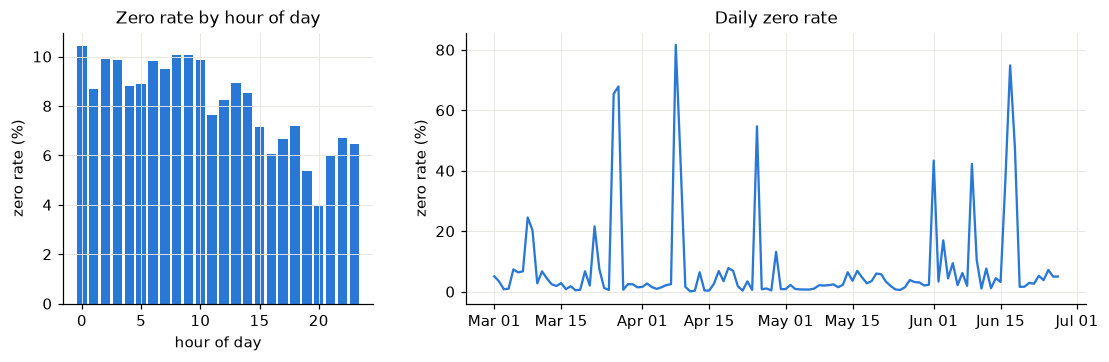

hours with highest zero rate: {0: 10.4, 8: 10.1, 9: 10.1}
days with highest zero rate: {Timestamp('2012-04-08 00:00:00'): 81.6, Timestamp('2012-06-17 00:00:00'): 74.9, Timestamp('2012-03-27 00:00:00'): 67.9, Timestamp('2012-03-26 00:00:00'): 65.4, Timestamp('2012-04-25 00:00:00'): 54.7}


In [7]:
zdf = pd.DataFrame(Z, index=df.index)
by_hour = zdf.mean(axis=1).groupby(df.index.hour).mean() * 100
by_day = zdf.mean(axis=1).resample("D").mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(by_hour.index, by_hour.values, color=C1, width=0.8)
ax[0].set(xlabel="hour of day", ylabel="zero rate (%)", title="Zero rate by hour of day")
ax[1].plot(by_day.index, by_day.values, color=C1)
ax[1].set(ylabel="zero rate (%)", title="Daily zero rate"); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
save(fig, "B3_zero_rate_by_hour_and_day")
print("hours with highest zero rate:", by_hour.nlargest(3).round(1).to_dict())
print("days with highest zero rate:", by_day.nlargest(5).round(1).to_dict())

**Takeaway.** 8.11% of all readings are zero, but most of it is structural: 2,148 timestamps (6.27%) are network-wide outages (97 runs, median 10 min, longest 31 h 45 min on Mar 26–27, 27 runs ≥ 1 h). Outside outages only 1.97% is missing. Per-sensor zero rates are tight (median 6.97%, max 20.1% for 718076), and the heatmap shows the remaining missingness is blocky (multi-hour gaps on specific sensors) rather than random. There's no strong hour-of-day effect (10.4% at midnight vs 8.1% overall). Several of the worst days (Jun 16–18) fall in the test period.

## C. Speed distribution

nonzero readings: 6,519,002; mean 58.46, median 63.22, std 13.02 mph
exact 70.0 values: 33,073 (0.51% of nonzero); values > 70: 0
nonzero values < 10 mph: 0.46%; < 20 mph: 2.91%
non-integer values: 87.31%
sensors with > 5% of readings exactly 70: 2; top: {'772669': 25.2, '718076': 5.3, '717481': 4.9}


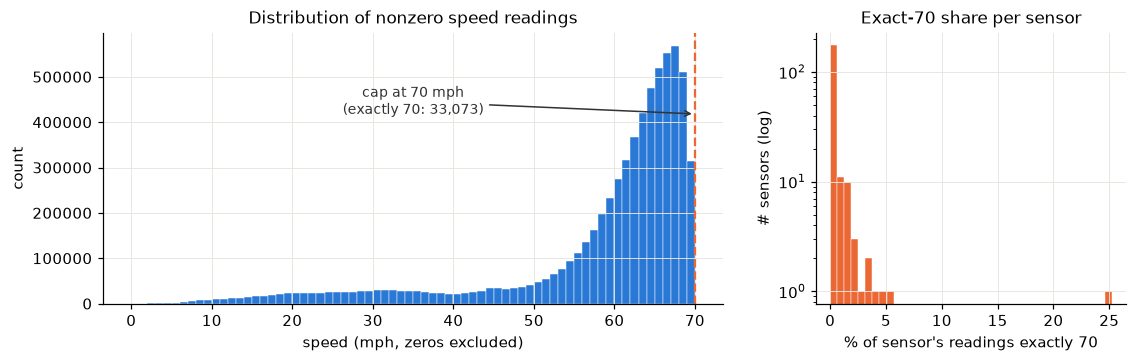

In [8]:
nz = V[~Z]
n70 = int((V == 70).sum())
print(f"nonzero readings: {nz.size:,}; mean {nz.mean():.2f}, median {np.median(nz):.2f}, std {nz.std():.2f} mph")
print(f"exact 70.0 values: {n70:,} ({n70 / nz.size:.2%} of nonzero); values > 70: {(V > 70).sum()}")
print(f"nonzero values < 10 mph: {(nz < 10).mean():.2%}; < 20 mph: {(nz < 20).mean():.2%}")
print(f"non-integer values: {(nz != np.round(nz)).mean():.2%}")
f70 = stats.frac_eq_70 * 100
print(f"sensors with > 5% of readings exactly 70: {(f70 > 5).sum()}; top: {f70.nlargest(3).round(1).to_dict()}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [2, 1]})
ax[0].hist(nz, bins=np.arange(0, 70.5, 1), color=C1, edgecolor="white", linewidth=0.3)
ax[0].axvline(70, color=C2, ls="--"); ymax = ax[0].get_ylim()[1]
ax[0].annotate(f"cap at 70 mph\n(exactly 70: {n70:,})", (70, ymax * .7), xytext=(35, ymax * .7), ha="center", color="#333", fontsize=9,
               arrowprops=dict(arrowstyle="->", color="#333"))
ax[0].set(xlabel="speed (mph, zeros excluded)", ylabel="count", title="Distribution of nonzero speed readings")
ax[1].hist(f70, bins=40, color=C2, edgecolor="white", linewidth=0.3); ax[1].set_yscale("log")
ax[1].set(xlabel="% of sensor's readings exactly 70", ylabel="# sensors (log)", title="Exact-70 share per sensor")
save(fig, "C1_speed_hist")

In [9]:
def longest_runs(v):
    change = np.r_[True, v[1:] != v[:-1]]
    rid = np.cumsum(change) - 1
    lens = np.bincount(rid); vals = v[change]
    ok = vals != 0
    best = np.argmax(np.where(ok, lens, 0)); best_n70 = np.argmax(np.where(ok & (vals != 70), lens, 0))
    return lens[best], vals[best], lens[best_n70], vals[best_n70]
stuck = pd.DataFrame([longest_runs(V[:, j]) for j in range(V.shape[1])], index=df.columns,
                     columns=["longest_run", "value", "longest_run_excl70", "value_excl70"])
print("longest identical nonzero run (steps): median", stuck.longest_run.median(), "max", stuck.longest_run.max())
print("sensors with an identical non-70 value for >= 3h (36 steps):", (stuck.longest_run_excl70 >= 36).sum())
print("sensors with an identical non-70 value for >= 1 day (288 steps):", (stuck.longest_run_excl70 >= 288).sum())
display(stuck.sort_values("longest_run_excl70", ascending=False).head(8))

longest identical nonzero run (steps): median 3.0 max 82
sensors with an identical non-70 value for >= 3h (36 steps): 1
sensors with an identical non-70 value for >= 1 day (288 steps): 0


,longest_run,value,longest_run_excl70,value_excl70
718076,82,64.000,82,64.000
718496,34,65.000,34,65.000
717804,33,52.000,33,52.000
772669,62,70.000,24,44.000
761003,5,69.000,5,69.000
717570,5,68.000,5,68.000
772597,5,69.125,5,69.125
774204,5,63.000,5,63.000


**Takeaway.** Nonzero speeds are left-skewed (median 63.2, mean 58.5 mph) with a long congested tail; only 2.9% are below 20 mph. The maximum is exactly 70.0 and nothing exceeds it, so 70 is a hard cap. Overall only 0.51% of readings sit exactly at 70, but it's concentrated: sensor 772669 reads exactly 70 for 25.2% of its samples (and has a 62-step run at 70), and only 2 sensors exceed 5%. Stuck sensors are rare: only 718076 repeats one non-70 value (64.0) for ≥ 3 h (82 steps ≈ 6.8 h, visible as the flat segment in D3). No sensor is stuck for a day.

## D. Temporal patterns

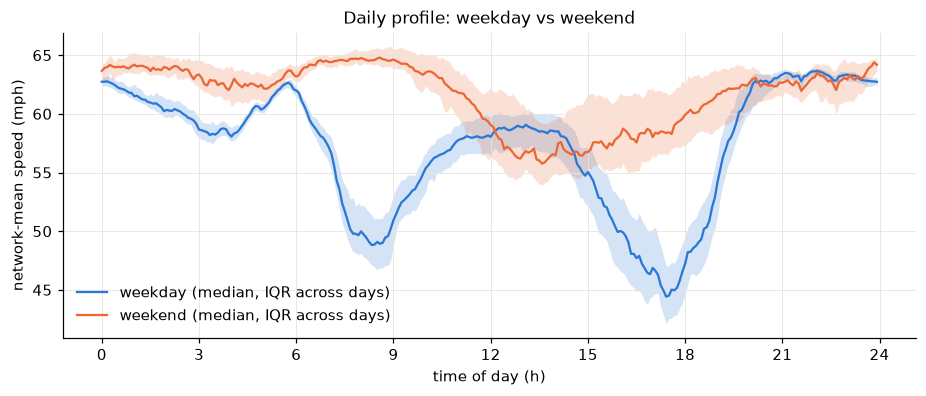

weekday AM dip: 48.8 mph at 08:20; PM dip: 44.4 mph at 17:25; night peak: 63.7 mph at 22:05
weekend minimum: 55.8 mph


In [10]:
# network-mean speed per timestamp (NaN during full outages)
net = pd.DataFrame(Vn, index=df.index).mean(axis=1)
tod = df.index.hour + df.index.minute / 60
wk = np.where(df.index.dayofweek < 5, "weekday", "weekend")
prof = pd.DataFrame({"v": net.values, "tod": tod, "wk": wk, "date": df.index.date})
piv = prof.pivot_table(index=["wk", "date"], columns="tod", values="v")
fig, ax = plt.subplots(figsize=(10, 3.6))
for (g, c) in [("weekday", C1), ("weekend", C2)]:
    q = piv.loc[g].quantile([.25, .5, .75])
    ax.fill_between(q.columns, q.loc[.25], q.loc[.75], color=c, alpha=.2, lw=0)
    ax.plot(q.columns, q.loc[.5], color=c, label=f"{g} (median, IQR across days)")
ax.set(xlabel="time of day (h)", ylabel="network-mean speed (mph)", title="Daily profile: weekday vs weekend", xticks=range(0, 25, 3))
ax.legend(loc="lower left")
save(fig, "D1_time_of_day_profile")
wd = piv.loc["weekday"].median()
am, pm = wd[(wd.index >= 5) & (wd.index < 11)], wd[(wd.index >= 14) & (wd.index < 20)]
fmt = lambda h: f"{int(h):02d}:{int(round(h % 1 * 60)):02d}"
print(f"weekday AM dip: {am.min():.1f} mph at {fmt(am.idxmin())}; PM dip: {pm.min():.1f} mph at {fmt(pm.idxmin())}; "
      f"night peak: {wd.max():.1f} mph at {fmt(wd.idxmax())}")
print(f"weekend minimum: {piv.loc['weekend'].median().min():.1f} mph")

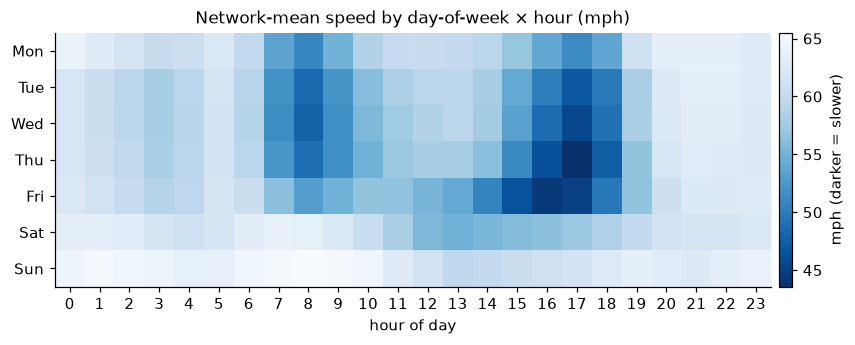

In [11]:
hm = net.groupby([df.index.dayofweek, df.index.hour]).mean().unstack()
hm.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(hm.values, aspect="auto", cmap="Blues_r"); ax.grid(False)
ax.set(xticks=range(24), yticks=range(7), yticklabels=hm.index, xlabel="hour of day", title="Network-mean speed by day-of-week × hour (mph)")
fig.colorbar(im, ax=ax, label="mph (darker = slower)", pad=0.01)
save(fig, "D2_dow_hour_heatmap")

{'congested (lowest mean)': ('771667', np.float64(30.9), '8.4%'), 'free-flowing (highest mean)': ('767455', np.float64(67.7), '10.4%'), 'high-missing (highest zero rate)': ('718076', np.float64(67.3), '20.1%')}


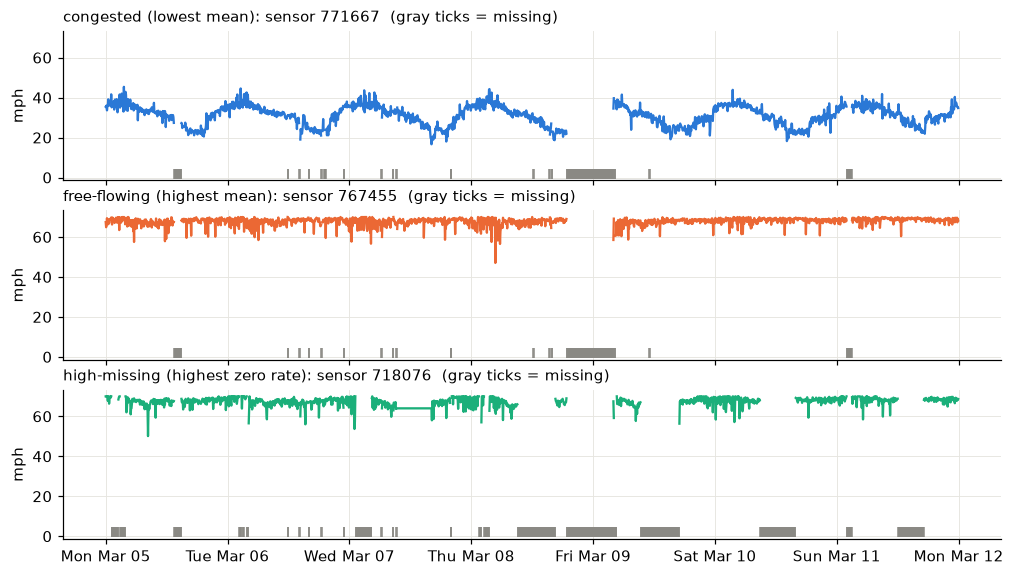

In [12]:
rep = {"congested (lowest mean)": stats.mean_nz.idxmin(),
       "free-flowing (highest mean)": stats.mean_nz.idxmax(),
       "high-missing (highest zero rate)": stats.zero_rate.idxmax()}
print({k: (s, round(stats.loc[s, 'mean_nz'], 1), f"{stats.loc[s, 'zero_rate']:.1%}") for k, s in rep.items()})
wk_slice = slice("2012-03-05", "2012-03-11")         # Mon-Sun
fig, axes = plt.subplots(len(rep), 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, ((lab, s), c) in zip(axes, zip(rep.items(), [C1, C2, C3])):
    x = df.loc[wk_slice, s]
    ax.plot(x.index, x.where(x > 0), color=c)
    miss = x.index[x == 0]
    ax.plot(miss, np.full(len(miss), 2), "|", color=GRAY, ms=6)
    ax.set_title(f"{lab}: sensor {s}  (gray ticks = missing)", loc="left", fontsize=10); ax.set_ylabel("mph")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %b %d"))
save(fig, "D3_sample_week")

**Takeaway.** Weekdays show two clear rush-hour dips in the network-mean speed: AM minimum 48.8 mph at 08:20 and a deeper PM minimum 44.4 mph at 17:25, against a night-time plateau of about 63.7 mph. Weekends are much flatter (minimum 55.8 mph, midday). The sample week shows the congested sensor tracking a smooth daily cycle, the free-flowing sensor near the cap, and the high-missing sensor with long gaps and a stuck segment. Time-of-day and day-of-week are therefore strong, cheap features.

## E. Long-term drift & holidays

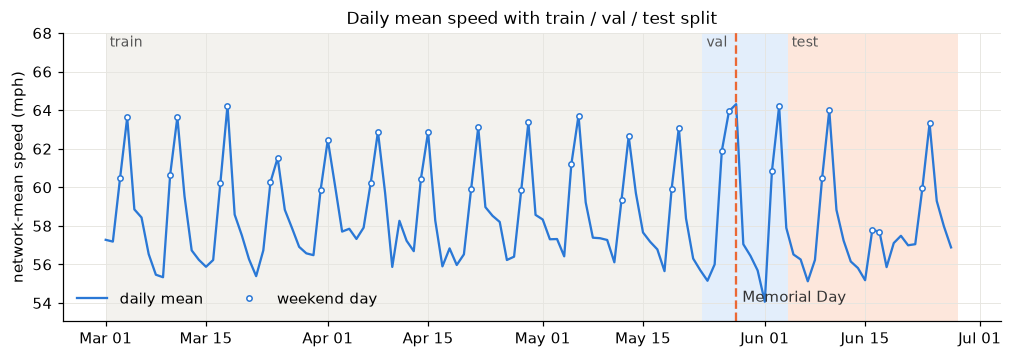

Memorial Day mean 64.31 mph vs other Mondays 58.79 ± 0.98; weekend days 61.58
monthly weekday means: {3: 57.04, 4: 57.57, 5: 57.34, 6: 56.73}


,start,end,steps,mean_nz,std_nz,zero_rate
train,2012-03-01 00:00:00,2012-05-23 07:05:00,23990,58.584,12.823,0.071
val,2012-05-23 07:10:00,2012-06-04 04:40:00,3427,58.899,13.182,0.07
test,2012-06-04 04:45:00,2012-06-27 23:55:00,6855,57.767,13.637,0.121


In [13]:
daily = net.resample("D").mean()
bounds = chrono_split(len(df))
fig, ax = plt.subplots(figsize=(11, 3.4))
for (name, (a, b)), c in zip(bounds.items(), ["#f3f2ee", "#e3eefb", "#fde7dc"]):
    ax.axvspan(df.index[a], df.index[b - 1], color=c, lw=0)
    ax.text(df.index[a], 67.3, f" {name}", fontsize=9, color="#555")
wkend = daily.index.dayofweek >= 5
ax.plot(daily.index, daily.values, color=C1, label="daily mean")
ax.plot(daily.index[wkend], daily.values[wkend], "o", color=C1, ms=3.5, mfc="white", label="weekend day")
md_day = pd.Timestamp("2012-05-28")
ax.axvline(md_day, color=C2, ls="--"); ax.annotate("Memorial Day", (md_day, daily.min()), xytext=(4, 0), textcoords="offset points", color="#333")
ax.set(ylabel="network-mean speed (mph)", title="Daily mean speed with train / val / test split", ylim=(daily.min() - 1, 68))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax.legend(loc="lower left", ncol=2)
save(fig, "E1_daily_mean_drift")

d = daily.to_frame("mean").assign(dow=daily.index.dayofweek, month=daily.index.month)
mondays = d[(d.dow == 0) & (d.index != md_day)]["mean"]
print(f"Memorial Day mean {daily[md_day]:.2f} mph vs other Mondays {mondays.mean():.2f} ± {mondays.std():.2f}; "
      f"weekend days {d[d.dow >= 5]['mean'].mean():.2f}")
print("monthly weekday means:", d[d.dow < 5].groupby("month")["mean"].mean().round(2).to_dict())
split_stats = pd.DataFrame({k: {"start": df.index[a], "end": df.index[b - 1], "steps": b - a,
                                "mean_nz": np.nanmean(Vn[a:b]), "std_nz": np.nanstd(Vn[a:b]), "zero_rate": Z[a:b].mean()}
                            for k, (a, b) in bounds.items()}).T
display(split_stats)

**Takeaway.** Weekday levels are stable across months (57.0 / 57.6 / 57.3 / 56.7 mph for Mar–Jun), so there's no large trend, but there is a slight June slowdown. Memorial Day (Mon 2012-05-28, in the validation split) looks like a weekend: 64.3 mph vs 58.8 ± 1.0 on other Mondays. The test split is slightly slower (57.8 vs 58.6 mph train) and has a much higher zero rate (12.1% vs 7.1%), which is a real train→test shift.

## F. Predictability (autocorrelation)

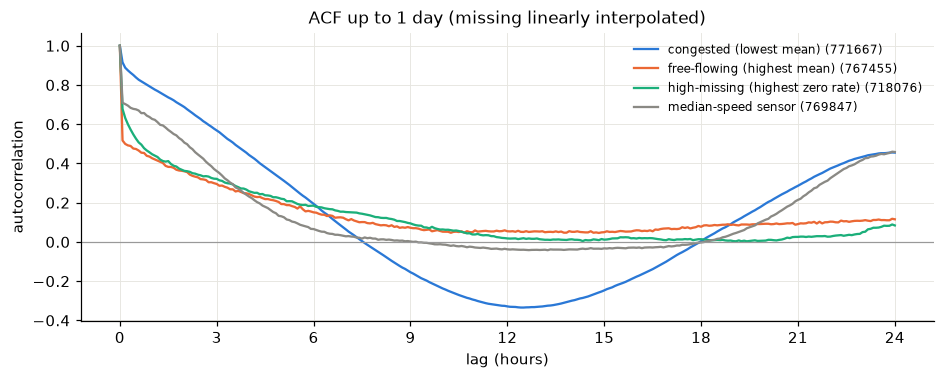

,5 min,15 min,30 min,1 h,1 day
mean,0.863,0.788,0.704,0.566,0.397
min,0.443,0.388,0.295,0.173,0.041
50%,0.917,0.842,0.758,0.601,0.434
max,0.980,0.947,0.900,0.798,0.667


In [14]:
Vi = pd.DataFrame(Vn, index=df.index, columns=df.columns).interpolate(limit_direction="both")  # for ACF only
acf_sensors = {**rep, "median-speed sensor": (stats.mean_nz - stats.mean_nz.median()).abs().idxmin()}
fig, ax = plt.subplots(figsize=(10, 3.4))
for (lab, s), c in zip(acf_sensors.items(), [C1, C2, C3, GRAY]):
    a = acf(Vi[s].values, nlags=288, fft=True)
    ax.plot(np.arange(289) * 5 / 60, a, color=c, label=f"{lab} ({s})")
ax.axhline(0, color="#999", lw=.8)
ax.set(xlabel="lag (hours)", ylabel="autocorrelation", title="ACF up to 1 day (missing linearly interpolated)", xticks=range(0, 25, 3))
ax.legend(fontsize=8, loc="upper right")
save(fig, "F1_acf")
lag_corr = pd.DataFrame({L: [Vi[s].autocorr(L) for s in df.columns] for L in [1, 3, 6, 12, 288]}, index=df.columns)
lag_corr.columns = ["5 min", "15 min", "30 min", "1 h", "1 day"]
display(lag_corr.describe().loc[["mean", "min", "50%", "max"]])

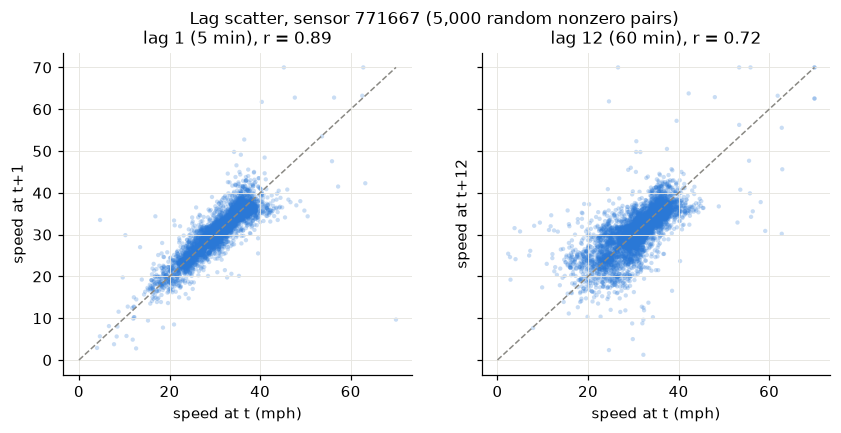

In [15]:
s = rep["congested (lowest mean)"]; x = df[s].values
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for a, L in zip(ax, [1, 12]):
    p, q = x[:-L], x[L:]; ok = (p > 0) & (q > 0)
    idx = rng.choice(np.flatnonzero(ok), 5000, replace=False)
    a.scatter(p[idx], q[idx], s=8, alpha=.25, color=C1, edgecolors="none")
    a.plot([0, 70], [0, 70], color=GRAY, ls="--", lw=1)
    r = np.corrcoef(p[ok], q[ok])[0, 1]
    a.set(title=f"lag {L} ({L * 5} min), r = {r:.2f}", xlabel="speed at t (mph)", ylabel=f"speed at t+{L}")
fig.suptitle(f"Lag scatter, sensor {s} (5,000 random nonzero pairs)", fontsize=11)
save(fig, "F2_lag_scatter")

**Takeaway.** Short-horizon persistence is strong: mean lag-1 (5 min) autocorrelation across sensors is 0.86, falling to 0.79 at 15 min, 0.70 at 30 min and 0.57 at 1 h. The daily (lag-288) correlation is 0.40 on average. Free-flowing sensors are dominated by measurement noise (ACF drops to ~0.5 after one step), while congested sensors have smooth, strongly periodic ACFs. So the achievable gain over persistence grows with horizon, and daily periodicity is what a historical-average probe exploits.

## G. Spatial structure & graph

adjacency sensor order matches h5 columns: True
locations: 207 rows, all sensors present: True


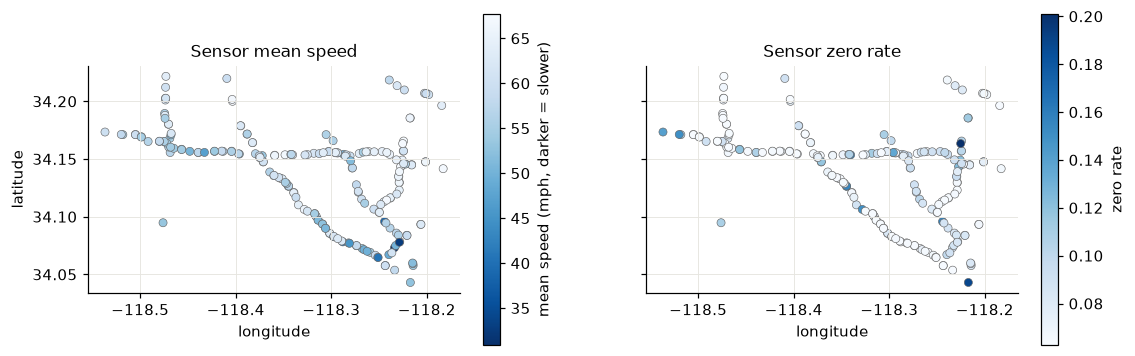

In [16]:
ids, id2ind, adj = load_adj(RAW_DIR / "adj_METR-LA.pkl", sensor_ids=list(df.columns))   # raises on order mismatch
loc = load_locations()
print("adjacency sensor order matches h5 columns: True")
if loc is None:
    print("graph_sensor_locations.csv not found -> run scripts/download_data.py; skipping map")
else:
    print(f"locations: {len(loc)} rows, all sensors present: {set(df.columns) <= set(loc.index)}")
    L = loc.loc[df.columns]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
    for a, col, cmap, lab in [(ax[0], "mean_nz", "Blues_r", "mean speed (mph, darker = slower)"),
                              (ax[1], "zero_rate", "Blues", "zero rate")]:
        sc = a.scatter(L.longitude, L.latitude, c=stats[col], cmap=cmap, s=28, edgecolors="#666", linewidths=0.4)
        fig.colorbar(sc, ax=a, label=lab, shrink=.85); a.set(xlabel="longitude"); a.set_aspect(1 / np.cos(np.radians(34.1)))
        a.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax[0].set(ylabel="latitude", title="Sensor mean speed"); ax[1].set(title="Sensor zero rate")
    save(fig, "G1_sensor_map")

adj: shape (207, 207), nonzero 1722 (incl. 207 self-loops), density (off-diag) 3.55%, symmetric: False
out-degree (excl. self): mean 7.3, median 7, min 0, max 18; isolated (no in/out edges): 1
nonzero off-diag weights: median 0.32, min 0.10


,pairs,raw_median,resid_median
bin,,,
0 (not linked),20008,0.173,0.046
"(0,.25]",488,0.336,0.091
"(.25,.5]",381,0.402,0.110
"(.5,.75]",234,0.537,0.310
"(.75,1]",210,0.817,0.646


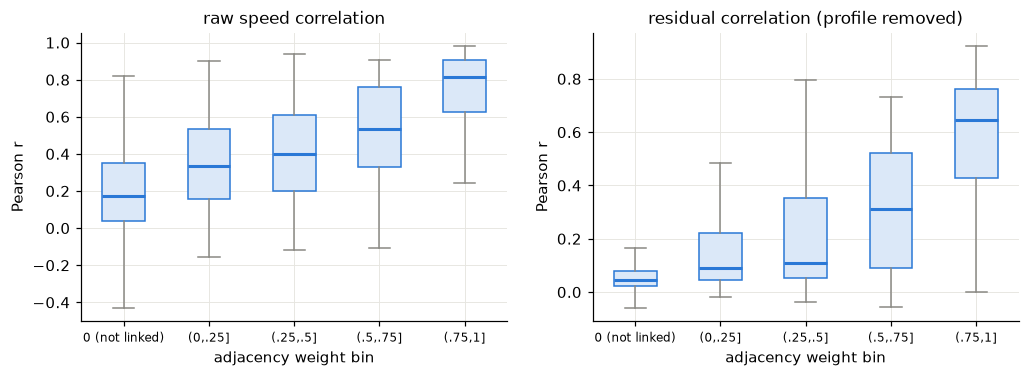

In [17]:
off = ~np.eye(len(adj), dtype=bool)
A = np.where(off, adj, 0)
out_deg, in_deg = (A > 0).sum(1), (A > 0).sum(0)
print(f"adj: shape {adj.shape}, nonzero {int((adj > 0).sum())} (incl. {int((np.diag(adj) > 0).sum())} self-loops), "
      f"density (off-diag) {(A > 0).sum() / off.sum():.2%}, symmetric: {np.allclose(adj, adj.T)}")
print(f"out-degree (excl. self): mean {out_deg.mean():.1f}, median {np.median(out_deg):.0f}, min {out_deg.min()}, max {out_deg.max()}; "
      f"isolated (no in/out edges): {int(((out_deg + in_deg) == 0).sum())}")
print(f"nonzero off-diag weights: median {np.median(A[A > 0]):.2f}, min {A[A > 0].min():.2f}")

# correlation: raw speeds and residuals after removing each sensor's (dow, time-of-day) profile
C_raw = pd.DataFrame(Vn).corr(min_periods=1000).values
slot = df.index.dayofweek * 288 + df.index.hour * 12 + df.index.minute // 5
resid = pd.DataFrame(Vn) - pd.DataFrame(Vn).groupby(slot).transform("mean").values
C_res = resid.corr(min_periods=1000).values
w = np.maximum(A, A.T)[np.triu_indices(len(A), 1)]           # undirected: max of both directions
cr, cs = C_raw[np.triu_indices(len(A), 1)], C_res[np.triu_indices(len(A), 1)]
bins = pd.cut(w, [-0.01, 0, 0.25, 0.5, 0.75, 1.0], labels=["0 (not linked)", "(0,.25]", "(.25,.5]", "(.5,.75]", "(.75,1]"])
tab = pd.DataFrame({"raw corr": cr, "residual corr": cs, "bin": bins}).groupby("bin", observed=True).agg(
    pairs=("raw corr", "size"), raw_median=("raw corr", "median"), resid_median=("residual corr", "median"))
display(tab)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for a, vals, t in [(ax[0], cr, "raw speed correlation"), (ax[1], cs, "residual correlation (profile removed)")]:
    data = [vals[(bins == b) & ~np.isnan(vals)] for b in tab.index]
    a.boxplot(data, showfliers=False, widths=.5, patch_artist=True,
              boxprops=dict(facecolor="#dbe8f8", edgecolor=C1), medianprops=dict(color=C1, lw=2),
              whiskerprops=dict(color=GRAY), capprops=dict(color=GRAY))
    a.set_xticks(range(1, len(tab) + 1), tab.index, fontsize=8); a.set(title=t, xlabel="adjacency weight bin", ylabel="Pearson r")
save(fig, "G2_corr_vs_adjacency")

**Takeaway.** All 207 locations are available and match the h5 order, as does the adjacency pickle (order verified; it's a 3-element list, not a tuple). The graph is directed (asymmetric), sparse (3.55% off-diagonal density; mean out-degree 7.3, max 18; one isolated sensor) and includes self-loops. Adjacency weight is clearly informative. The median raw correlation rises from 0.17 for unlinked pairs to 0.82 for weight > 0.75. After removing each sensor's weekly profile, the residual correlation still rises from 0.05 to 0.65, so neighbours share *non-periodic* congestion dynamics that a graph model can exploit.

## Evaluation protocol & non-neural probes

* **Split:** chronological 70/10/20 on *timestamps first*, then 12→12 sliding windows **within** each split (no window crosses a boundary → no leakage).
* **Normalization:** single global z-score from nonzero *train* values; missing inputs are set to 0 *after* normalization (= train mean) and the mask is kept (optionally as an extra input channel).
* **Metrics:** masked MAE / RMSE / MAPE (positions with ground truth 0 excluded) at horizons 3/6/12 (15/30/60 min).

,start,end,timestamps,windows (12->12)
train,2012-03-01 00:00:00,2012-05-23 07:05:00,23990,23967
val,2012-05-23 07:10:00,2012-06-04 04:40:00,3427,3404
test,2012-06-04 04:45:00,2012-06-27 23:55:00,6855,6832


train mean 58.584 mph, std 12.823 mph  ->  a raw 0 would z-score to -4.57
train input windows: 23,967
  windows with >=1 missing input value (any sensor): 91.8%
  (window, sensor) input sequences with >=1 missing step: 10.3%; fully missing: 5.48%
  windows touching a network-wide outage: 8.0%
  masked target positions (train): 7.1%


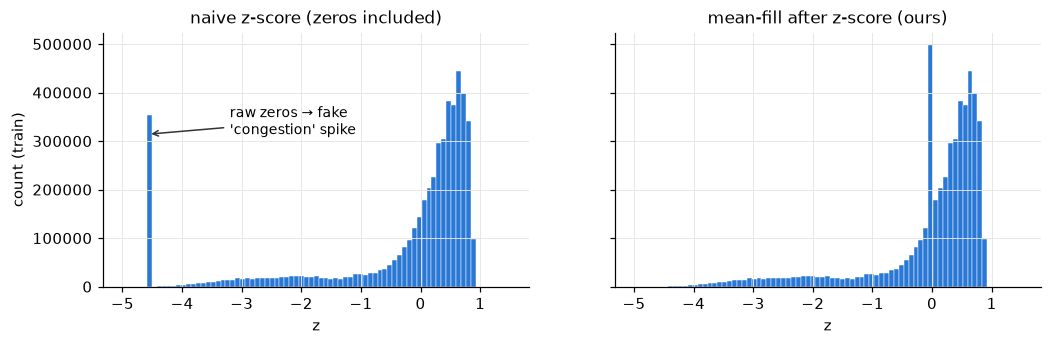

In [18]:
split_tab = pd.DataFrame({k: {"start": df.index[a], "end": df.index[b - 1], "timestamps": b - a,
                              "windows (12->12)": b - a - 23} for k, (a, b) in bounds.items()}).T
display(split_tab)
a, b = bounds["train"]
scaler = zscore_fit(V[a:b])
print(f"train mean {scaler.mean:.3f} mph, std {scaler.std:.3f} mph  ->  a raw 0 would z-score to {(0 - scaler.mean) / scaler.std:.2f}")

_, _, xm, ym = make_windows(V[a:b], ~Z[a:b])
x_missing = ~xm                                     # (W, 12, N) True = missing
az_tr = all_zero[a:b]
touch_outage = np.lib.stride_tricks.sliding_window_view(az_tr, 24)[:, :12].any(1)
print(f"train input windows: {len(xm):,}")
print(f"  windows with >=1 missing input value (any sensor): {x_missing.any((1, 2)).mean():.1%}")
print(f"  (window, sensor) input sequences with >=1 missing step: {x_missing.any(1).mean():.1%}; fully missing: {x_missing.all(1).mean():.2%}")
print(f"  windows touching a network-wide outage: {touch_outage.mean():.1%}")
print(f"  masked target positions (train): {(~ym).mean():.1%}")

tr = V[a:b].ravel()
naive = (tr - scaler.mean) / scaler.std
filled = scaler.transform(V[a:b], ~Z[a:b]).ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for a_, v, t in [(ax[0], naive, "naive z-score (zeros included)"), (ax[1], filled, "mean-fill after z-score (ours)")]:
    a_.hist(v, bins=np.linspace(-5, 1.5, 80), color=C1, edgecolor="white", linewidth=0.3); a_.set(title=t, xlabel="z")
ax[0].annotate("raw zeros → fake\n'congestion' spike", ((0 - scaler.mean) / scaler.std, ax[0].get_ylim()[1] * .6), xytext=(-3.2, ax[0].get_ylim()[1] * .6),
               arrowprops=dict(arrowstyle="->", color="#333"), fontsize=9)
ax[0].set_ylabel("count (train)")
save(fig, "EV1_normalization_missing")

test windows: 6,832; masked target positions: 12.1%


horizon                               15 min                30 min        \
                                         MAE  RMSE MAPE (%)    MAE  RMSE   
model                                                                      
Historical average (dow × tod, train)   4.19  7.86    13.06   4.19  7.86   
Persistence (last observed)             3.71  7.47     8.94   4.62  9.64   

horizon                                        60 min                  
                                      MAPE (%)    MAE   RMSE MAPE (%)  
model                                                                  
Historical average (dow × tod, train)    13.06   4.19   7.86    13.06  
Persistence (last observed)              11.48   6.14  12.61    15.69

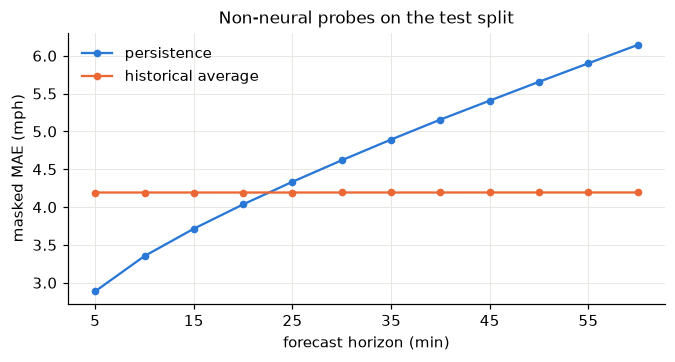

In [19]:
s, e = bounds["test"]
x_te, y_te, _, ym_te = make_windows(V[s:e], ~Z[s:e])
x_te = x_te[..., 0]
print(f"test windows: {len(y_te):,}; masked target positions: {(~ym_te).mean():.1%}")

pred_last = persistence(x_te)
ha = fit_historical_average(df.iloc[a:b])
ha_t = historical_average(ha, df.index[s:e])                                   # (T_test, N)
pred_ha = np.lib.stride_tricks.sliding_window_view(ha_t, 24, axis=0).transpose(0, 2, 1)[:, 12:]

rows = []
for name, p in [("Persistence (last observed)", pred_last), ("Historical average (dow × tod, train)", pred_ha)]:
    for hz, m in horizon_report(p, y_te).items():
        rows.append({"model": name, "horizon": hz, **m})
res = pd.DataFrame(rows).pivot(index="model", columns="horizon").swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
res = res[[(h, m) for h in ["15 min", "30 min", "60 min"] for m in ["MAE", "RMSE", "MAPE (%)"]]]
res.round(2).to_csv(FIG / "probe_results.csv")
display(res.round(2))

per_h = pd.DataFrame({name: [float(masked_mae(p[:, h], y_te[:, h])) for h in range(12)]
                      for name, p in [("persistence", pred_last), ("historical average", pred_ha)]}, index=np.arange(1, 13) * 5)
fig, ax = plt.subplots(figsize=(7, 3.2))
for (col, c) in zip(per_h.columns, [C1, C2]):
    ax.plot(per_h.index, per_h[col], "o-", color=c, ms=4, label=col)
ax.set(xlabel="forecast horizon (min)", ylabel="masked MAE (mph)", title="Non-neural probes on the test split", xticks=range(5, 65, 10))
ax.legend()
save(fig, "EV2_probe_mae_by_horizon")

In [20]:
meta = prepare_processed()          # caches data/processed/{metr_la_processed.npz, meta.json} for CI2/CI3
print(json.dumps({k: meta[k] for k in ["splits", "split_times", "mean", "std", "missing_fill"]}, indent=1, default=str))

{
 "splits": {
  "train": [
   0,
   23990
  ],
  "val": [
   23990,
   27417
  ],
  "test": [
   27417,
   34272
  ]
 },
 "split_times": {
  "train": [
   "2012-03-01 00:00:00",
   "2012-05-23 07:05:00"
  ],
  "val": [
   "2012-05-23 07:10:00",
   "2012-06-04 04:40:00"
  ],
  "test": [
   "2012-06-04 04:45:00",
   "2012-06-27 23:55:00"
  ]
 },
 "mean": 58.58425765022911,
 "std": 12.822883207357794,
 "missing_fill": "0.0 after z-score (= train mean); mask stored separately"
}


**Takeaway.** Splitting timestamps first gives 23,967 / 3,404 / 6,832 train/val/test windows (each split loses the 23 windows that would straddle its end boundary, 46 total vs window-then-split). Train stats: mean 58.58, std 12.82 mph, so a raw 0 would become z = −4.57, a huge fake 'congestion' spike. Mean-fill removes it (EV1). Missingness can't be ignored in inputs: 91.8% of train windows have at least one missing value somewhere, 10.3% of (window, sensor) inputs have a missing step, 5.48% are fully missing, and 8.0% of windows touch a network-wide outage. On the test split, persistence wins at 15 min (MAE 3.71) but degrades quickly (4.62 at 30 min, 6.14 at 60 min), while the historical average is flat at 4.19. **The bar for the neural model is therefore 3.71 / 4.19 / 4.19 MAE at 15 / 30 / 60 min** (best probe per horizon).

## H. Likely failure modes

Each item is grounded in the analyses above.

1. **Outages and imputed zeros in targets and inputs.** 6.27% of timestamps are network-wide zeros (up to 31 h 45 min), and the test split has a zero rate of 12.1% vs 7.1% in train. If zeros aren't masked, the loss rewards predicting 0 and metrics are inflated or deflated. *Mitigation:* masked loss and metrics, mean-fill after z-score, and an optional mask channel.
2. **Post-outage recovery.** After a long outage the input window is all-missing, so the model has no recent context and must fall back to the time-of-day prior. Expect error spikes on windows that follow outages (8.0% of train windows touch one).
3. **Sudden congestion onset.** The largest errors should occur at rush-hour onset (steep drops 06:00–08:20 and 14:30–17:25 in D1), where persistence and HA both fail. This is where spatial (upstream) information should help most (G2 residual correlations).
4. **70-mph cap.** Targets are clipped at 70, so errors near free-flow are artificially small and the model may under-predict at the cap. Sensor 772669 (25% exactly 70) likely reports a capped or default value and deserves a per-sensor error check.
5. **Stuck or unreliable sensors.** 718076 has a 6.8-h constant segment and the highest missingness (20.1%). Constant values are *not* masked, so the model can be trained on and scored against fake readings.
6. **Non-stationarity and holidays.** Memorial Day behaves like a weekend (+5.5 mph vs typical Mondays) and sits in the validation split, which can bias early stopping. The test period (June) is slightly slower and its day-of-week pattern may differ as schools end (unverified).
7. **Heterogeneous sensors.** Mean speeds range from 31 to 68 mph. A shared-weight model evaluated with a global MAE will be dominated by the congested minority, so we'll report per-sensor error distributions, not just the mean.